# Actividad. Tarea 1. Construcción de panel de calidad de aire 2025


Datos: https://aire.cdmx.gob.mx/default.php?opc=%27aKBh%27

#### Fuente de datos

Los datos son extraidos de la Red Automática de Monitoreo Atmosférico (RAMA) de la Ciudad de México. Se he elegido **P$_{2.5}$** como contaminante de estudio. 





#### P$_{2.5}$

Las partículas P$_{2.5}$ son partículas finas de hasta $2.5 \mu m$ cuya fuente principal proviene de motores diésel, calefacción con leña o carbón, industrias, generación eléctrica, humo de incendios forestales. Su composición típica consiste de elementos como: hollín, sulfatos, nitratos, compuestos orgánicos volátiles secundarios. Tiene vida larga en el aire (días a semanas) por lo que puede desplazarse largas distancias.

Se considera un contaminante prioritario en términos de salud pública por su capacidad de llegar a los alveolos y pasar al torrente sanguíneo. Está relacionado con enfermedades cardivasculares, pulmonares, daño cerebral y efectos adversos en el embarazo.

El límite de concentración en aire, estipulado por organismos internacionales como la OMS, es $5 \frac{\mu g}{m^3}$ como promedio anual.

## 1. Preparación de los datos
- cargar la base;
- identificar las estaciones disponibles;
- sustituir los valores `-99` por `NaN`;
- construir la variable `timestamp` a partir de `FECHA` y `HORA`;
- verificar:
  - primer y último instante;
  - número de observaciones;
  - duplicados;
  - frecuencia temporal;
  - regularidad horaria.

### Cargar la base

Los datos tienen la siguiente estructura:
- Primera columna `[FECHA]`: Fecha de monitoreo con formato (día/mes/año).
- Segunda columna `[HORA]`: Hora de monitoreo (horas 1 a 24).
- A partir de la tercera columna: Concentración del contaminante por estación de 
  monitoreo. Las estaciones se identifican con la clave de la estación. 
- Los datos nulos se identifican con la etiqueta -99.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

La base de datos contiene 8760 filas y 24 columnas

In [2]:
# Cargar directamente del directorio

df= pd.read_excel("2025PM25.xls")

print("Dimensiones de la base de datos: ")
print("Filas: ",df.shape[0],"  Columnas: ",df.shape[1])
df.head(20)

Dimensiones de la base de datos: 
Filas:  8760   Columnas:  24


,FECHA,HORA,AJM,AJU,BJU,CAM,CCA,FAR,GAM,HGM,...,MPA,NEZ,PED,SAC,SAG,SFE,TLA,UAX,UIZ,XAL
0,2025-01-01,1,13,54,-99,40,30,-99,-99,44,...,15,105,33,126,-99,-99,71,81,47,-99
1,2025-01-01,2,12,28,-99,71,36,-99,-99,38,...,12,155,33,151,-99,-99,90,131,67,-99
2,2025-01-01,3,11,35,-99,105,42,-99,-99,50,...,13,174,45,177,-99,-99,54,146,73,-99
3,2025-01-01,4,14,23,-99,105,52,-99,-99,59,...,13,166,39,162,-99,-99,96,111,100,-99
4,2025-01-01,5,15,15,-99,81,61,-99,-99,74,...,11,234,43,152,-99,-99,18,83,112,-99
5,2025-01-01,6,13,11,-99,80,50,-99,-99,90,...,12,268,41,162,-99,-99,19,112,92,-99
6,2025-01-01,7,16,11,-99,72,54,-99,-99,139,...,15,263,38,147,-99,-99,32,148,91,-99
7,2025-01-01,8,10,13,-99,56,48,-99,-99,102,...,12,239,32,207,-99,-99,3,135,122,-99
8,2025-01-01,9,10,10,-99,62,38,-99,-99,116,...,12,171,34,189,-99,-99,2,132,174,-99
9,2025-01-01,10,28,12,-99,61,39,-99,-99,173,...,14,177,46,246,-99,-99,13,106,166,-99


Vemos que todas las columnas son del tipo `int` a excepción de la columna fecha que es del tipo `datetime`. Es necesario el tipado correcto para la columna `HORA`, que posteriormente se anexará a la columna `FECHA` para crear la variable `timestamp` que contendrá fecha-hora.

In [3]:
df.dtypes

FECHA    datetime64[us]
HORA              int64
AJM               int64
AJU               int64
BJU               int64
CAM               int64
CCA               int64
FAR               int64
GAM               int64
HGM               int64
INN               int64
MER               int64
MGH               int64
MON               int64
MPA               int64
NEZ               int64
PED               int64
SAC               int64
SAG               int64
SFE               int64
TLA               int64
UAX               int64
UIZ               int64
XAL               int64
dtype: object

### Identificar las estaciones disponibles

Las estaciones disponibles corresponden apartir de la tercera columna del DataFrame. Todas estas columnas representan las estaciones y sus observaciones las concentraciones de **PM2.5**.

In [4]:
estaciones=[]
for col in df.columns:
    if col not in ["FECHA","HORA"]:
        estaciones.append(col)

print("El número de estaciones disponibles son: ",len(estaciones))
print("\nEstaciones: ",estaciones)

El número de estaciones disponibles son:  22

Estaciones:  ['AJM', 'AJU', 'BJU', 'CAM', 'CCA', 'FAR', 'GAM', 'HGM', 'INN', 'MER', 'MGH', 'MON', 'MPA', 'NEZ', 'PED', 'SAC', 'SAG', 'SFE', 'TLA', 'UAX', 'UIZ', 'XAL']


### Sustituir los valores `-99` por `NaN`

Los NA de nuestra base de datos tienen entrada `-99`. La información dada por `.info()` no indica ausencia de valores nulos. 

Realizamos la transformación $ -99 \longrightarrow \text{NaN}$

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 24 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   FECHA   8760 non-null   datetime64[us]
 1   HORA    8760 non-null   int64         
 2   AJM     8760 non-null   int64         
 3   AJU     8760 non-null   int64         
 4   BJU     8760 non-null   int64         
 5   CAM     8760 non-null   int64         
 6   CCA     8760 non-null   int64         
 7   FAR     8760 non-null   int64         
 8   GAM     8760 non-null   int64         
 9   HGM     8760 non-null   int64         
 10  INN     8760 non-null   int64         
 11  MER     8760 non-null   int64         
 12  MGH     8760 non-null   int64         
 13  MON     8760 non-null   int64         
 14  MPA     8760 non-null   int64         
 15  NEZ     8760 non-null   int64         
 16  PED     8760 non-null   int64         
 17  SAC     8760 non-null   int64         
 18  SAG     8760 non-nu

Vamos a contar los valores nulos en el DataFrame. Para las columnas estaciones generamos boleanos True si el valor es -99, sumamos y ordenamos.

In [6]:
valores_menores_99= df[estaciones].eq(-99).sum().sort_values(ascending=False)
valores_menores_99

SFE    8760
MGH    8760
XAL    8760
MON    8594
HGM    7572
SAG    7275
AJU    6659
SAC    4206
INN    4114
BJU    3837
CAM    3516
AJM    3058
UIZ    2916
FAR    2685
MPA    2542
GAM    2398
NEZ    1812
TLA    1205
MER    1091
UAX     936
PED     899
CCA     140
dtype: int64

El **porcentaje de datos faltantes por columna**. Existe un gran porcentaje de datos faltantes. Hay estaciones como 
- SFE, MGH, XAL que tienen el 100% de datos faltantes. No hay datos válidos en el periodo analizado.
- Todas las columnas desde XAL hasta GAM tienen cobertura parcial.
- NEZ, TLA, MER, UAX, PED tienen del 10% al 20% de datos faltantes.
- CCA tiene 1.6% de datos faltantes.

Si proponemos un umbral $≥85\%$ de cobertura, las estaciones válidas son:
- CCA 1.6% datos faltantes.
- PED 10.3% datos faltantes.
- UAX 10.7% datos faltantes.
- MER 12.5% datos faltantes.
- TLA 13.76% datos faltantes.


In [7]:
valores_menores_99 / len(df) 

SFE    1.000000
MGH    1.000000
XAL    1.000000
MON    0.981050
HGM    0.864384
SAG    0.830479
AJU    0.760160
SAC    0.480137
INN    0.469635
BJU    0.438014
CAM    0.401370
AJM    0.349087
UIZ    0.332877
FAR    0.306507
MPA    0.290183
GAM    0.273744
NEZ    0.206849
TLA    0.137557
MER    0.124543
UAX    0.106849
PED    0.102626
CCA    0.015982
dtype: float64

Sustituir `-99` por `NaN`. Ahora vamos a reemplazar los valores. Una vez reemplazados los valores a `NaN` podemos usar la función usual `.isna()` y sumar con `sum()`. 


In [8]:
df[estaciones]=df[estaciones].replace(-99,np.nan)
print("El número de valores NaN es: ", df.isna().sum().sum())
print("El número de valores NaN por columna: \n",df[estaciones].isna().sum().sort_values(ascending=False))


El número de valores NaN es:  91735
El número de valores NaN por columna: 
 SFE    8760
MGH    8760
XAL    8760
MON    8594
HGM    7572
SAG    7275
AJU    6659
SAC    4206
INN    4114
BJU    3837
CAM    3516
AJM    3058
UIZ    2916
FAR    2685
MPA    2542
GAM    2398
NEZ    1812
TLA    1205
MER    1091
UAX     936
PED     899
CCA     140
dtype: int64


Creo una nueva lista de estaciones que cumplen el umbral de  $≥85\%$ de cobertura, es decir aquellas estaciones que tienen a lo más $15\%$ de datos faltantes.

Defino una lista de las estaciones ordenada de mayor a menor en valores de NaN. Defino un umbral de 15% de datos faltantes (cobertura de 85%). Agrego a la lista `estaciones_umbral` las que cumplan:
- Que no sean columnas "FECHA","HORA"
- Y que no excedan el umbral.


In [9]:
valores_NA= df.isna().sum().sort_values(ascending=False)

estaciones_umbral=[]
umbral=.15

for col in df.columns:
    if col not in ["FECHA","HORA"] and valores_NA[col]/len(df)<= umbral:
        estaciones_umbral.append(col)
        
print("Estaciones que cumplen umbral: ", estaciones_umbral)

Estaciones que cumplen umbral:  ['CCA', 'MER', 'PED', 'TLA', 'UAX']


Así, se puede acceder a un DataFrame en el que solamente están las estaciones con buena cobertura ($≥85\%$). CCA es la estación con mayor cobertura con sólo $≥1.6\%$ de datos faltantes. 

In [10]:
df[estaciones_umbral]

,CCA,MER,PED,TLA,UAX
0,30.0,NaN,33.0,71.0,81.0
1,36.0,NaN,33.0,90.0,131.0
2,42.0,NaN,45.0,54.0,146.0
3,52.0,NaN,39.0,96.0,111.0
4,61.0,NaN,43.0,18.0,83.0
...,...,...,...,...,...
8755,28.0,NaN,43.0,26.0,18.0
8756,33.0,NaN,36.0,21.0,20.0
8757,29.0,NaN,41.0,30.0,20.0
8758,27.0,NaN,37.0,52.0,29.0


Hacemos `.drop(columns= ["","",...,""])` de las columnas que no cumplan en umbral. Restamos estaciones-estaciones_umbral como resta de conjuntos.

In [11]:
df_umbral= df.drop(columns= set(estaciones).difference( set(estaciones_umbral) ))
df_umbral

,FECHA,HORA,CCA,MER,PED,TLA,UAX
0,2025-01-01,1,30.0,NaN,33.0,71.0,81.0
1,2025-01-01,2,36.0,NaN,33.0,90.0,131.0
2,2025-01-01,3,42.0,NaN,45.0,54.0,146.0
3,2025-01-01,4,52.0,NaN,39.0,96.0,111.0
4,2025-01-01,5,61.0,NaN,43.0,18.0,83.0
...,...,...,...,...,...,...,...
8755,2025-12-31,20,28.0,NaN,43.0,26.0,18.0
8756,2025-12-31,21,33.0,NaN,36.0,21.0,20.0
8757,2025-12-31,22,29.0,NaN,41.0,30.0,20.0
8758,2025-12-31,23,27.0,NaN,37.0,52.0,29.0


### Construir la variable `timestamp` a partir de `FECHA` y `HORA`

Vamos a crear una nueva variable `timestamp` que combina
- `FECHA`
- `HORA`

La variable resultante es `timestamp` con formato: (fecha - hora)



In [12]:
# Creamos una copia para tener la base inicial sin editar. 
p25=df.copy()

Verificarmos el tipo de variable que tenemos en cada variable.


In [13]:
p25[["FECHA","HORA"]].dtypes

FECHA    datetime64[us]
HORA              int64
dtype: object

Vemos que la columna fecha es del tipo datetime, aún así hacemos la tranformación con fines metodológicos. Si no se puede transformar el valor es `NaT`

In [14]:
p25["FECHA"]=pd.to_datetime(p25["FECHA"], errors="coerce")

Convertimos la columna "HORA" en un objeto tipo `timedelta`. "h" indica horas

In [15]:
p25["HORA"]=pd.to_timedelta(p25["HORA"],unit="h")

p25[["FECHA","HORA"]].dtypes

FECHA    datetime64[us]
HORA     timedelta64[s]
dtype: object

**Creamos la variable `timestamp`**

In [16]:
p25["timestamp"]=p25["FECHA"]+p25["HORA"]
p25.head(4)

,FECHA,HORA,AJM,AJU,BJU,CAM,CCA,FAR,GAM,HGM,...,NEZ,PED,SAC,SAG,SFE,TLA,UAX,UIZ,XAL,timestamp
0,2025-01-01,0 days 01:00:00,13.0,54.0,NaN,40.0,30.0,NaN,NaN,44.0,...,105.0,33.0,126.0,NaN,NaN,71.0,81.0,47.0,NaN,2025-01-01 01:00:00
1,2025-01-01,0 days 02:00:00,12.0,28.0,NaN,71.0,36.0,NaN,NaN,38.0,...,155.0,33.0,151.0,NaN,NaN,90.0,131.0,67.0,NaN,2025-01-01 02:00:00
2,2025-01-01,0 days 03:00:00,11.0,35.0,NaN,105.0,42.0,NaN,NaN,50.0,...,174.0,45.0,177.0,NaN,NaN,54.0,146.0,73.0,NaN,2025-01-01 03:00:00
3,2025-01-01,0 days 04:00:00,14.0,23.0,NaN,105.0,52.0,NaN,NaN,59.0,...,166.0,39.0,162.0,NaN,NaN,96.0,111.0,100.0,NaN,2025-01-01 04:00:00


Ordenamos cronológicamente según la columna `timestamp`. Crea nuevo indexado, eliminando los índices anteriores.


In [17]:
p25=p25.sort_values("timestamp").reset_index(drop=True)

### Verificar
Verificamos los valores que no pudieron construirse

In [18]:
print("\nValores de `timestamp` que no se pudieron transformar: ")
print(p25["timestamp"].isna().sum())


Valores de `timestamp` que no se pudieron transformar: 
0


#### primer y último instante

In [19]:
print("\nPrimer instante: ")
print(p25["timestamp"].min())

print("\nÚltimo instante: ")
print(p25["timestamp"].max())


Primer instante: 
2025-01-01 01:00:00

Último instante: 
2026-01-01 00:00:00


#### número de observaciones

In [20]:
print("\nEl número de observaciones: " )
print(len(p25["timestamp"]))



El número de observaciones: 
8760


#### duplicados

In [21]:
print("\nNúmero de timestamps duplicados: ")
print(p25["timestamp"].duplicated().sum())


Número de timestamps duplicados: 
0


#### frecuencia temporal

Separación entre observaciones consecutivas. Si las observaciones son regulares esperamos encontrar
$$
\Delta t_i=t_i-t_{i-1}=1\text{ hora}
$$
`pd.infer_freq()` para verificar si `pandas` reconoce automáticamente una frecuencia horaria.

In [22]:
# Índice temporal
p25_temporal= p25.set_index("timestamp").sort_index()


Se detecta automáticamente una frecuencia horaria. Es una secuencia regular, así que el calendario temporal está completo.

In [23]:
frecuencia_inferida= pd.infer_freq(p25_temporal.index)
print("Frecuencia inferida: ")
frecuencia_inferida

Frecuencia inferida: 


'h'

#### regularidad horaria



Se calcula la diferencia entre cada elemento de la serie. Los elementos son del tipo `timestamp`.

In [24]:
delta_t=p25_temporal.index.to_series().diff()
delta_t

timestamp
2025-01-01 01:00:00               NaT
2025-01-01 02:00:00   0 days 01:00:00
2025-01-01 03:00:00   0 days 01:00:00
2025-01-01 04:00:00   0 days 01:00:00
2025-01-01 05:00:00   0 days 01:00:00
                            ...      
2025-12-31 20:00:00   0 days 01:00:00
2025-12-31 21:00:00   0 days 01:00:00
2025-12-31 22:00:00   0 days 01:00:00
2025-12-31 23:00:00   0 days 01:00:00
2026-01-01 00:00:00   0 days 01:00:00
Name: timestamp, Length: 8760, dtype: timedelta64[us]

Resumen de los intervalos existentes. Quita el primer valor pues no hay diferencia con el primer índice. Cuenta y ordena

In [25]:
print("\nIntervalos observados:")
delta_t.dropna().value_counts().sort_index()


Intervalos observados:


timestamp
0 days 01:00:00    8759
Name: count, dtype: int64

Cuenta los valores no nulos o los invalos válidos. Cuenta cuántos intervalos son exactamente de una hora. Se hace la proporción de intervalos de una hora respecto al total.

In [26]:
# Verificación de intervalos horarios


n_intervalos= delta_t.notna().sum()

n_intervalos_horarios= (
    delta_t==pd.Timedelta(hours=1)).sum()

porcentaje_horario = n_intervalos_horarios / n_intervalos * 100

print(f"\nNúmero de intervalos evaluados: {n_intervalos}")
print(f"Porcentaje de intervalos horarios: {porcentaje_horario:.2f}%")


Número de intervalos evaluados: 8759
Porcentaje de intervalos horarios: 100.00%


### Calendario temporal regular
El calendario temporal es regular. Los 8759 intervalos entre observaciones son de una hora. Hay $T=8760$ instantes horarios esperados.



## 2. Diagnóstico de calidad por estación
Para cada estación calcular:

- número de observaciones esperadas;
- observaciones disponibles;
- valores faltantes;
- porcentaje de cobertura;
- número de huecos temporales;
- longitud del hueco máximo en horas y días.

Utilizar como criterios iniciales de selección:

$$
\text{cobertura}\geq90\%
$$

y

$$
\text{hueco máximo}\leq48\text{ horas}.
$$

Mostrar gráficamente la cobertura de las estaciones y justificar cuáles serán conservadas para el análisis.

### Número de observaciones esperadas

In [27]:
n_esperadas= len(p25_temporal)
n_esperadas

8760

### Observaciones disponibles


In [28]:
n_disponibles= p25_temporal[estaciones].notna().sum()
n_disponibles

AJM    5702
AJU    2101
BJU    4923
CAM    5244
CCA    8620
FAR    6075
GAM    6362
HGM    1188
INN    4646
MER    7669
MGH       0
MON     166
MPA    6218
NEZ    6948
PED    7861
SAC    4554
SAG    1485
SFE       0
TLA    7555
UAX    7824
UIZ    5844
XAL       0
dtype: int64

### Valores faltantes

In [29]:
n_faltantes= p25_temporal[estaciones].isna().sum()
n_faltantes

AJM    3058
AJU    6659
BJU    3837
CAM    3516
CCA     140
FAR    2685
GAM    2398
HGM    7572
INN    4114
MER    1091
MGH    8760
MON    8594
MPA    2542
NEZ    1812
PED     899
SAC    4206
SAG    7275
SFE    8760
TLA    1205
UAX     936
UIZ    2916
XAL    8760
dtype: int64

### Porcentaje de Cobertura


In [30]:
cobertura=pd.DataFrame({"n_esperadas":n_esperadas , "n_disponibles":n_disponibles , "n_faltantes":n_faltantes })
print(cobertura.shape)
cobertura

(22, 3)


,n_esperadas,n_disponibles,n_faltantes
AJM,8760,5702,3058
AJU,8760,2101,6659
BJU,8760,4923,3837
CAM,8760,5244,3516
CCA,8760,8620,140
FAR,8760,6075,2685
GAM,8760,6362,2398
HGM,8760,1188,7572
INN,8760,4646,4114
MER,8760,7669,1091


In [76]:
cobertura["cobertura_pct"]= cobertura["n_disponibles"]/ cobertura["n_esperadas"]*100

cobertura= cobertura.sort_values("cobertura_pct",ascending=False)
cobertura.round(2)

,n_esperadas,n_disponibles,n_faltantes,cobertura_pct
CCA,8760,8620,140,98.40
PED,8760,7861,899,89.74
UAX,8760,7824,936,89.32
MER,8760,7669,1091,87.55
TLA,8760,7555,1205,86.24
NEZ,8760,6948,1812,79.32
GAM,8760,6362,2398,72.63
MPA,8760,6218,2542,70.98
FAR,8760,6075,2685,69.35
UIZ,8760,5844,2916,66.71


### Visualización de la cobertura por estación 

In [77]:
# 
cobertura_ordenada= cobertura["cobertura_pct"].sort_values(ascending=True)

# Número de estaciones que cumplen el criterio. Tomé 85% de cobertura para tener más estaciones.
n_seleccionadas= (cobertura["cobertura_pct"]>=85).sum()

print("El número de estaciones con cobertura >=85 :",n_seleccionadas," de " , len(cobertura))



El número de estaciones con cobertura >=85 : 5  de  22


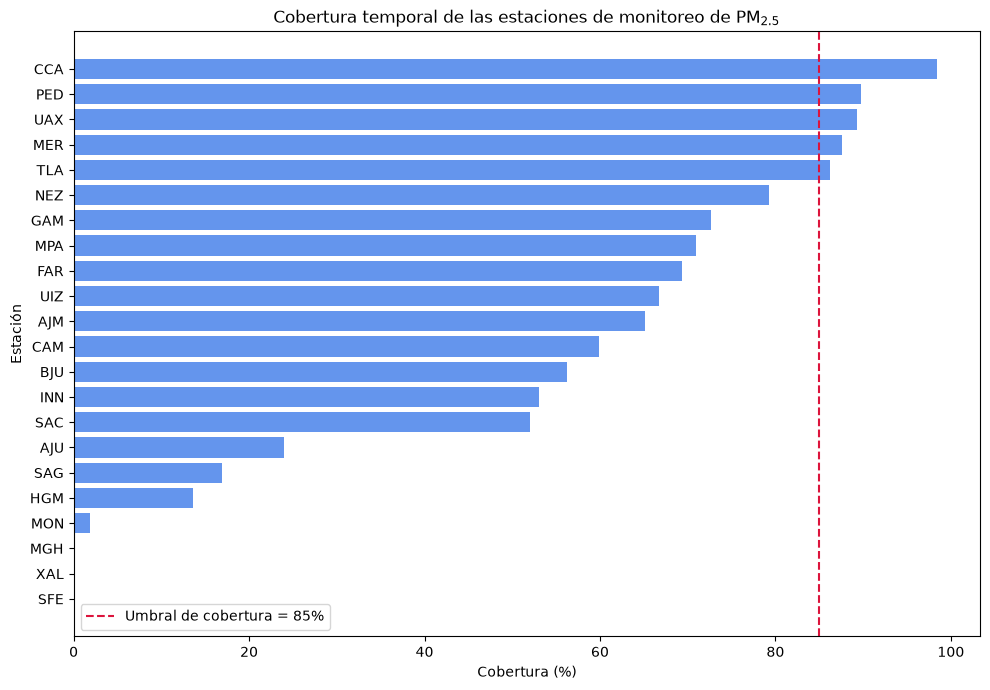

In [78]:
# Graficar 
fig,ax = plt.subplots(figsize=(10,7))

ax.barh(    # Gráfico de barras
    cobertura_ordenada.index,
    cobertura_ordenada.values, color="cornflowerblue"
)

ax.axvline(x=85, linestyle="--",linewidth=1.5,
           label="Umbral de cobertura = 85%",color="crimson")    # Linea que representa 85%

# Etiquetas
ax.set_title("Cobertura temporal de las estaciones de monitoreo de PM$_{2.5}$")
ax.set_xlabel("Cobertura (%)")
ax.set_ylabel("Estación")

ax.legend()
plt.tight_layout()
plt.savefig("cobertura_estaciones.png", dpi=300)
plt.show()



### Números de huecos temporales
Analizar la estructura de faltantes nos permite ver los faltantes aislados o las interrupciones prolongadas. Los huecos tienen longitud $$g$$

Podemos expresar la duración en días
$$
G_{\mathrm{días}}
=
\frac{G_{\mathrm{horas}}}{24}.
$$

In [79]:
# Funcion para análisis de huecos

def resumen_huecos(serie):
    # Crea una serie booleana
    faltante=serie.isna()
    
    # si no existen valores faltantes
    if faltante.sum()==0:
        return pd.Series({"n_faltantes":0 ,"n_huecos":0 ,"hueco_max_horas":0})

    # Identificador de bloques consecutivos
    grupos= faltante.ne(faltante.shift()).cumsum()

    # Longitud de cada bloque compuesto por NaN
    longitudes= (faltante[faltante].groupby(grupos[faltante]).size() )

    return pd.Series({"n_faltantes": int(faltante.sum()) , "n_huecos":len(longitudes) , "hueco_max_horas": int(longitudes.max()) })

In [80]:
huecos= pd.DataFrame({ estacion: resumen_huecos(p25_temporal[estacion])
            for estacion in estaciones
                     }).T
huecos

,n_faltantes,n_huecos,hueco_max_horas
AJM,3058,68,2227
AJU,6659,28,6264
BJU,3837,40,1936
CAM,3516,72,3168
CCA,140,60,12
FAR,2685,120,1705
GAM,2398,85,1139
HGM,7572,38,7358
INN,4114,138,1900
MER,1091,112,129


### Longitud del hueco máximo en horas y días

In [84]:
# De la cobertura 
huecos["cobertura_pct"]=cobertura["cobertura_pct"]

# Convertimos el hueco máximo a días
huecos["hueco_max_dias"]= huecos["hueco_max_horas"]/24

# Ordenamos por cobertura
huecos= huecos[ ["cobertura_pct","n_faltantes","n_huecos","hueco_max_horas","hueco_max_dias"] ].sort_values("cobertura_pct",ascending=False)
huecos.round(2)

,cobertura_pct,n_faltantes,n_huecos,hueco_max_horas,hueco_max_dias
CCA,98.40,140,60,12,0.50
PED,89.74,899,88,421,17.54
UAX,89.32,936,59,457,19.04
MER,87.55,1091,112,129,5.38
TLA,86.24,1205,82,397,16.54
NEZ,79.32,1812,43,1169,48.71
GAM,72.63,2398,85,1139,47.46
MPA,70.98,2542,67,1925,80.21
FAR,69.35,2685,120,1705,71.04
UIZ,66.71,2916,62,1211,50.46


In [85]:
print("\nHuecos en estaciones con cobertura >=90%: ")

display( huecos[ huecos["cobertura_pct"]>=90 ].sort_values("hueco_max_horas",ascending=True).round(2) )


Huecos en estaciones con cobertura >=90%: 


,cobertura_pct,n_faltantes,n_huecos,hueco_max_horas,hueco_max_dias
CCA,98.4,140,60,12,0.5


In [86]:
print("\nHuecos en estaciones con cobertura >=85%: ")

display( huecos[ huecos["cobertura_pct"]>=85 ].sort_values("hueco_max_horas",ascending=True).round(2) )


Huecos en estaciones con cobertura >=85%: 


,cobertura_pct,n_faltantes,n_huecos,hueco_max_horas,hueco_max_dias
CCA,98.40,140,60,12,0.50
MER,87.55,1091,112,129,5.38
TLA,86.24,1205,82,397,16.54
PED,89.74,899,88,421,17.54
UAX,89.32,936,59,457,19.04


### Representación gráfica de la cobertura de las estaciones y continuidad temporal

Dos referencias:

$$
C_i \geq 80\%
$$

y un hueco máximo de

$$
G_i \leq 48\text{ horas},
$$

equivalente a dos días consecutivos sin información. La selección final deberá considerar conjuntamente ambos indicadores y no únicamente el porcentaje de cobertura.


In [87]:
huecos.head(3)

,cobertura_pct,n_faltantes,n_huecos,hueco_max_horas,hueco_max_dias
CCA,98.401826,140,60,12,0.500000
PED,89.737443,899,88,421,17.541667
UAX,89.315068,936,59,457,19.041667


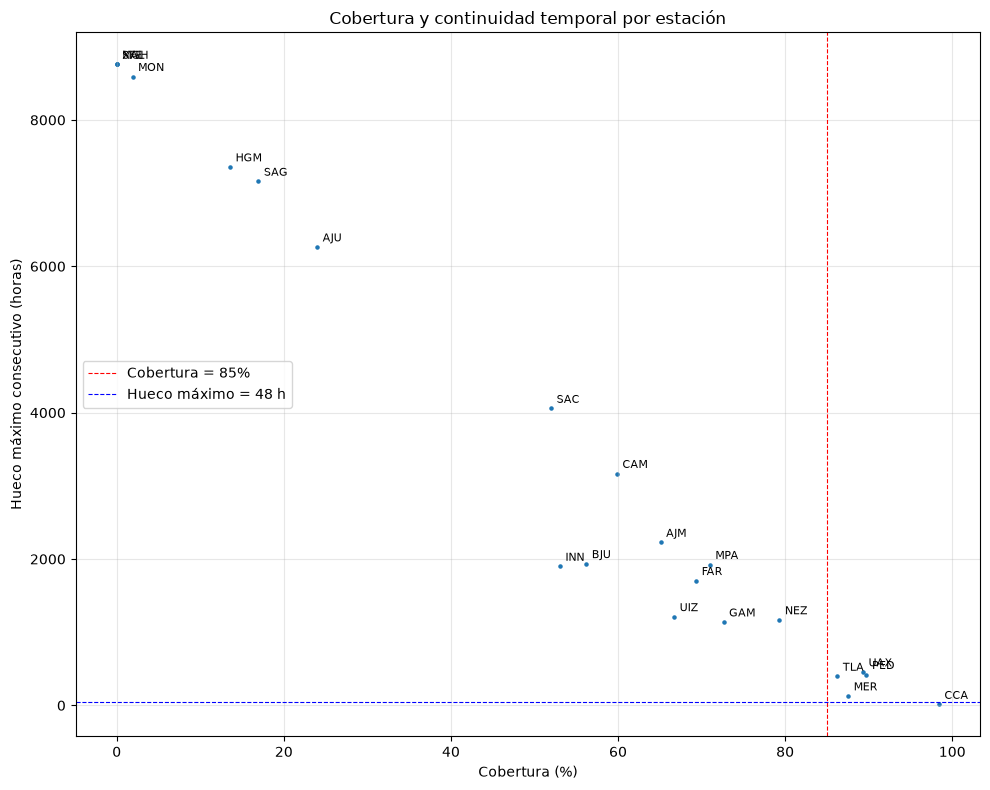

In [110]:
# Cobertura vs hueco temporal máximo

fig, ax =plt.subplots( figsize=( 10,8) )

ax.scatter(
    huecos["cobertura_pct"],
    huecos["hueco_max_horas"],
    s=5
)

# Etiquetas
for estacion,fila in huecos.iterrows():
    ax.annotate(
        estacion,
        (fila["cobertura_pct"],fila["hueco_max_horas"]), 
        xytext=(4,4),
        textcoords="offset points",
        fontsize=8
    )

ax.axvline(x=85, linestyle="--",linewidth=.8,
           label="Cobertura = 85%",color="red")    # Linea que representa 85%

ax.axhline(48, linestyle="--",linewidth=.8,
          label="Hueco máximo = 48 h", color ='blue')


ax.set_title("Cobertura y continuidad temporal por estación")
ax.set_xlabel("Cobertura (%)")
ax.set_ylabel("Hueco máximo consecutivo (horas)")

ax.legend()

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Estaciones que cumplen ambos criterios

Dos referencias:

$$
C_i \geq 85\%
$$

y un hueco máximo de

$$
G_i \leq 48\text{ horas},
$$

Vemos que la única estación que cumple ambos criterios es `CCA`. 

In [113]:
criterio_cobertura= huecos["cobertura_pct"]>=90

criterio_hueco= huecos["hueco_max_horas"]<=48

candidatas= huecos[criterio_cobertura & criterio_hueco].copy()

print("Estaciones que cumplen ambos criterios: ")
print(candidatas.index.tolist())

print("\nNúmero de estaciones")
print(len(candidatas))

candidatas

Estaciones que cumplen ambos criterios: 
['CCA']

Número de estaciones
1


,cobertura_pct,n_faltantes,n_huecos,hueco_max_horas,hueco_max_dias
CCA,98.401826,140,60,12,0.5


## 3. Disponibilidad simultánea de la red
Para las estaciones seleccionadas calcular, en cada instante,

$$
P_t=
\frac{\text{número de estaciones disponibles en }t}
{\text{número de estaciones seleccionadas}}
\times100.
$$

Identificar los periodos de baja disponibilidad utilizando

$$
P_t<50\%.
$$

Determinar:

- número de episodios;
- inicio y final de cada episodio;
- duración;
- número mínimo de estaciones disponibles.



Disponibilidad simultánea de la red de estaciones para detectar momentos en los que la cobertura es insuficiente. $P_t$ calcula el porcentaje de estacione. Que tan completa es la red. Cuando menos de la mitad de las estaciones estan disponibles simultáneamente $P_t <50\%$. Una vez detectados los periodos de baja disponibilidad se analizan.
- Número de episodios: cuántas veces ocurre la condición $P_t <50\%$
- Inicio y final de cada episodio: los intervalos de tiempo en que la red estuvo por debajo del umbral.
- Duración: cuánto tiempo duró cada episodio.
- Número mínimo de estaciones disponibles: el punto más crítico dentro de cada episodio.

Se mide la robustez de la red de monitoreo y localizar momentos en que la información es poco confiable porque hay demasiadas estaciones fuera de servicio.



#### Resumen
Primero se analiza la red con 19 estaciones activas. Se calcula
- $P_t$ porcentaje de estaciones disponibles por hora.
- Se detectan episodios con $P_t<50\%$
- Para la red completa se obtienen 168 episodios de baja disponibilidad.


Luego se analiza solo el panel seleccionado, que al final es `CCA`
- 8620 horas con dato
- 140 horas sin dato
- 60 episodios de baja disponibilidad

Se grafica la evolución temporal de disponibilidad y una matriz de disponibilidad horaria.

In [37]:
# Estaciones con al menos una medición válida
estaciones_activas= cobertura.index[ cobertura["n_disponibles"]>0 ] 

n_estaciones_activas= len(estaciones_activas)

print("Número total de estaciones en la base: ")
print(len(estaciones))

print("\nEstaciones con al menos una medición válida: ")
print(n_estaciones_activas)

Número total de estaciones en la base: 
22

Estaciones con al menos una medición válida: 
19


In [38]:
# Disponibilidad en la red

disponibilidad_red= pd.DataFrame( index= p25_temporal.index)

disponibilidad_red["n_estaciones"] = p25_temporal[estaciones_activas].notna().sum(axis=1)

disponibilidad_red["porcentaje"] = disponibilidad_red["n_estaciones"] / n_estaciones_activas *100

disponibilidad_red

,n_estaciones,porcentaje
timestamp,,
2025-01-01 01:00:00,13,68.421053
2025-01-01 02:00:00,13,68.421053
2025-01-01 03:00:00,13,68.421053
2025-01-01 04:00:00,13,68.421053
2025-01-01 05:00:00,13,68.421053
...,...,...
2025-12-31 20:00:00,11,57.894737
2025-12-31 21:00:00,11,57.894737
2025-12-31 22:00:00,11,57.894737


In [39]:
# 
print("\nResumen del número de estaciones disponibles por hora: ")
display( disponibilidad_red["n_estaciones"].describe().round(2).to_frame() )

print("\nResumen del porcentaje de disponibilidad de la red: ")
display( disponibilidad_red["porcentaje"].describe().round(2).to_frame() )


Resumen del número de estaciones disponibles por hora: 


,n_estaciones
count,8760.00
mean,11.53
std,2.72
min,3.00
25%,10.00
50%,11.00
75%,14.00
max,17.00



Resumen del porcentaje de disponibilidad de la red: 


,porcentaje
count,8760.00
mean,60.67
std,14.34
min,15.79
25%,52.63
50%,57.89
75%,73.68
max,89.47


In [40]:
# Instantes con menor disponibilidad

minimo_estaciones= disponibilidad_red["n_estaciones"].min()

print("\nMenor número de estaciones disponibles simultáneamente: ")
print(minimo_estaciones)

print("\nInstantes en los que se alcanzó el mínimo: ")
display( disponibilidad_red[ disponibilidad_red["n_estaciones"]==minimo_estaciones ].head(20) )


Menor número de estaciones disponibles simultáneamente: 
3

Instantes en los que se alcanzó el mínimo: 


,n_estaciones,porcentaje
timestamp,,
2025-01-12 11:00:00,3,15.789474
2025-01-12 12:00:00,3,15.789474
2025-06-15 04:00:00,3,15.789474
2025-06-15 05:00:00,3,15.789474
2025-06-15 06:00:00,3,15.789474


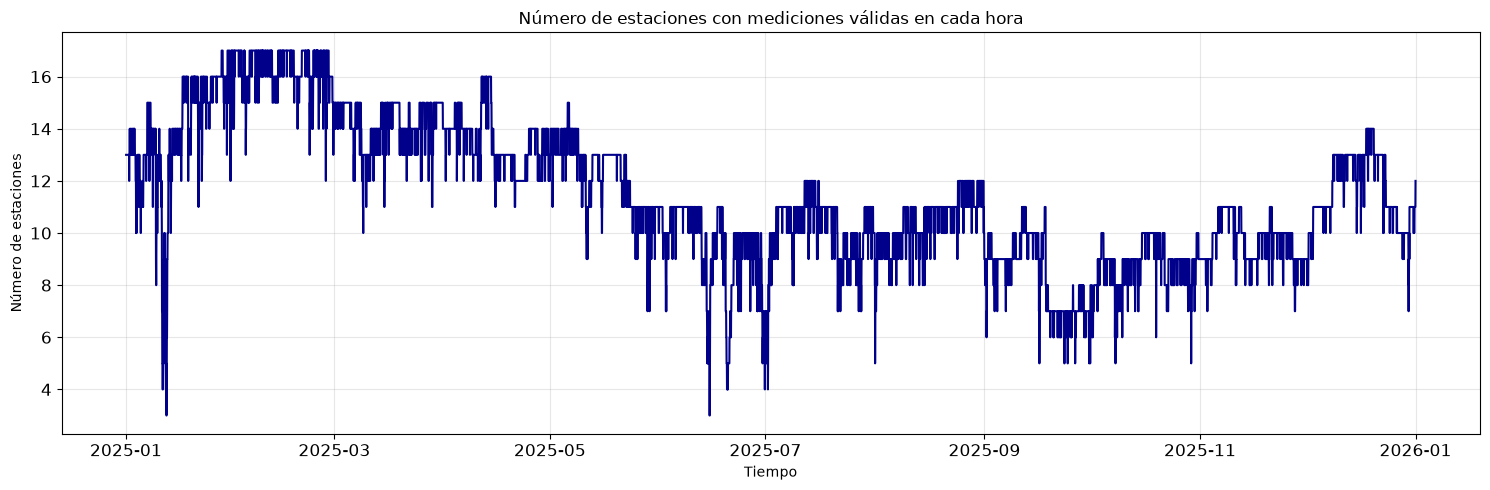

In [41]:
# Evolución temporal

fig,ax = plt.subplots( figsize=(15,5) )

ax.plot( disponibilidad_red.index, disponibilidad_red["n_estaciones"],color="darkblue" )

ax.set_title("Número de estaciones con mediciones válidas en cada hora")

ax.set_xlabel("Tiempo")
ax.set_ylabel("Número de estaciones")
ax.tick_params(labelsize=12)

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [42]:
### 
# Identificación de episodios de baja disponibilidad
umbral=50

disponibilidad_red["baja_disponibilidad"]= disponibilidad_red["porcentaje"]<umbral


In [43]:
# Identificación de bloques consecutivos

grupos = (
    disponibilidad_red["baja_disponibilidad"]
    .ne(
        disponibilidad_red["baja_disponibilidad"].shift()
    )
    .cumsum()
)


episodios = []

for _, bloque in disponibilidad_red[
    disponibilidad_red["baja_disponibilidad"]
].groupby(
    grupos[disponibilidad_red["baja_disponibilidad"]]
):

    episodios.append({
        "inicio": bloque.index.min(),
        "fin": bloque.index.max(),
        "duracion_horas": len(bloque),
        "min_estaciones": bloque["n_estaciones"].min(),
        "min_porcentaje": bloque["porcentaje"].min(),
        "media_estaciones": bloque["n_estaciones"].mean()
    })


episodios_baja_disponibilidad = pd.DataFrame(episodios)

episodios_baja_disponibilidad

,inicio,fin,duracion_horas,min_estaciones,min_porcentaje,media_estaciones
0,2025-01-09 12:00:00,2025-01-09 14:00:00,3,8,42.105263,8.333333
1,2025-01-11 05:00:00,2025-01-11 19:00:00,15,4,21.052632,5.866667
2,2025-01-12 01:00:00,2025-01-12 18:00:00,18,3,15.789474,6.111111
3,2025-05-11 10:00:00,2025-05-11 10:00:00,1,9,47.368421,9.000000
4,2025-05-11 14:00:00,2025-05-11 16:00:00,3,9,47.368421,9.000000
...,...,...,...,...,...,...
163,2025-12-28 08:00:00,2025-12-28 09:00:00,2,9,47.368421,9.000000
164,2025-12-28 12:00:00,2025-12-28 12:00:00,1,9,47.368421,9.000000
165,2025-12-28 17:00:00,2025-12-28 17:00:00,1,9,47.368421,9.000000
166,2025-12-30 00:00:00,2025-12-30 04:00:00,5,7,36.842105,8.400000


In [44]:
print("\nNúmero de episodios de baja disponibilidad:")
len(episodios_baja_disponibilidad)


Número de episodios de baja disponibilidad:


168

#### Resumen
Para cada estación:
- observaciones esperadas
- disponibles
- faltantes
- cobertura
- número de huecos
- hueco máximo en horas y días

Se grafica:
- Cobertura por estación.
- Cobertura contra hueco máximo

Criterios de selección
- cobertura $≥90\%$
- hueco máximo $≤48$ h

Donde sólo `CCA` cumple ambos criterios.
- $Cobertura: 98.40%$
- Hueco máximo: 12 h
- Faltantes: 140


In [125]:
estaciones_finales= candidatas.index.to_list()

p25_horario = p25.set_index("timestamp")[estaciones].sort_index()


p25_seleccionado= p25_horario[estaciones_finales].copy()

p25_seleccionado

,CCA
timestamp,
2025-01-01 01:00:00,30.0
2025-01-01 02:00:00,36.0
2025-01-01 03:00:00,42.0
2025-01-01 04:00:00,52.0
2025-01-01 05:00:00,61.0
...,...
2025-12-31 20:00:00,28.0
2025-12-31 21:00:00,33.0
2025-12-31 22:00:00,29.0


In [132]:
# Faltantes después de la selección 

n_total= p25_seleccionado.size
n_faltantes=p25_seleccionado.isna().sum().sum()

print("\nNúmero total de valores posibles: ")
print(n_total)

print("\nNúmero total de valores faltantes: ")
print(n_faltantes)

print("\nPorcentaje global de faltantes: ")
print( f"{100* n_faltantes/n_total:.2f}%" )


Número total de valores posibles: 
8760

Número total de valores faltantes: 
140

Porcentaje global de faltantes: 
1.60%


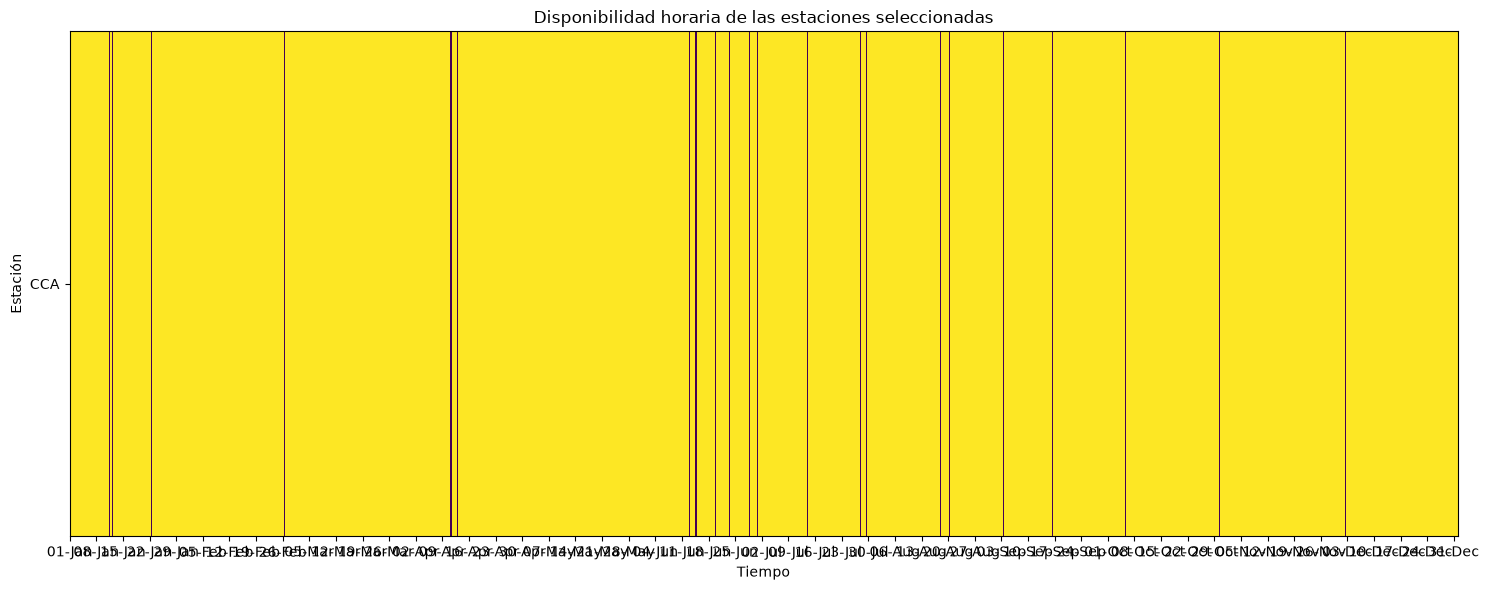

In [150]:
# Matriz de disponibilidad

matriz_disponibilidad= p25_seleccionado.notna().astype(int).T


fig, ax = plt.subplots(figsize=(15, 6))

ax.imshow(
    matriz_disponibilidad,
    aspect="auto",
    interpolation="nearest"
)

ax.set_title("Disponibilidad horaria de las estaciones seleccionadas")
ax.set_ylabel("Estación")
ax.set_xlabel("Tiempo")

ax.set_yticks(np.arange(len(estaciones_finales)))
ax.set_yticklabels(estaciones_finales)


paso = 24 * 7

posiciones = np.arange(0,len(p25_seleccionado),paso)
etiquetas = p25_seleccionado.index[posiciones].strftime("%d-%b")

ax.set_xticks(posiciones)
ax.set_xticklabels(etiquetas)

plt.tight_layout()
plt.show()

### Disponibilidad simultánea del panel seleccionado



In [158]:
# Disponibilidad simultánea del panel seleccionado
disponibilidad_panel= pd.DataFrame( index= p25_seleccionado.index )

disponibilidad_panel["n_disponibles"]= p25_seleccionado.notna().sum(axis=1)

disponibilidad_panel["porcentaje_disponible"]= disponibilidad_panel["n_disponibles"] / len(estaciones_finales)*100

print("Resumen del número de estaciones disponibles por hora: ")

display(disponibilidad_panel["n_disponibles"].describe().round(2).to_frame())


# Horas completamente observadas 
n_completas= (disponibilidad_panel["n_disponibles"]== len(estaciones_finales) ).sum()

# 
print("\nHoras con las estaciones disponibles (CCA) :")

print(n_completas)
print(f"Porcentaje: "f"{100 * n_completas / len(disponibilidad_panel):.2f}%")


# Horas sin ninguna estación disponible
n_sin_datos = (
    disponibilidad_panel["n_disponibles"] == 0
).sum()

print("\nHoras sin ninguna estación disponible:")
print(n_sin_datos)

print(f"Porcentaje: "f"{100 * n_sin_datos / len(disponibilidad_panel):.2f}%")


# Distribución de disponibilidad
print("\nNúmero de horas según estaciones disponibles:")

display(
    disponibilidad_panel["n_disponibles"]
    .value_counts().sort_index(ascending=False).rename("n_horas").to_frame()
)

Resumen del número de estaciones disponibles por hora: 


,n_disponibles
count,8760.00
mean,0.98
std,0.13
min,0.00
25%,1.00
50%,1.00
75%,1.00
max,1.00



Horas con las estaciones disponibles (CCA) :
8620
Porcentaje: 98.40%

Horas sin ninguna estación disponible:
140
Porcentaje: 1.60%

Número de horas según estaciones disponibles:


,n_horas
n_disponibles,
1,8620
0,140


In [159]:
# Horas con menos del 50% de las estaciones disponibles

umbral_simultaneo = 50

horas_baja_disponibilidad = disponibilidad_panel[
    disponibilidad_panel["porcentaje_disponible"]
    < umbral_simultaneo
]

print(f"\nHoras con disponibilidad < {umbral_simultaneo}%:")

print(len(horas_baja_disponibilidad))

display(horas_baja_disponibilidad)


Horas con disponibilidad < 50%:
140


,n_disponibles,porcentaje_disponible
timestamp,,
2025-01-11 07:00:00,0,0.0
2025-01-11 08:00:00,0,0.0
2025-01-11 09:00:00,0,0.0
2025-01-11 10:00:00,0,0.0
2025-01-11 11:00:00,0,0.0
...,...,...
2025-12-02 14:00:00,0,0.0
2025-12-22 22:00:00,0,0.0
2025-12-22 23:00:00,0,0.0


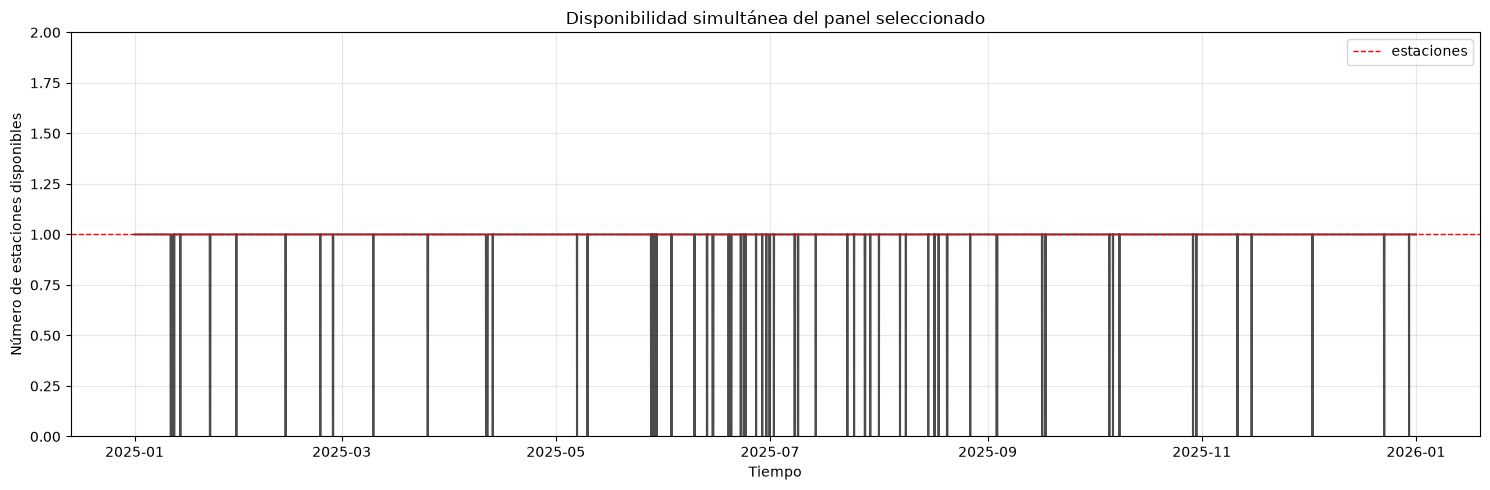

In [164]:
# Evolución temporal

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    disponibilidad_panel.index,
    disponibilidad_panel["n_disponibles"], color ='black', alpha=0.7
)

ax.axhline(len(estaciones_finales),linestyle="--",
    linewidth=1,label="estaciones", color='red'
)

ax.set_title("Disponibilidad simultánea del panel seleccionado")

ax.set_xlabel("Tiempo")
ax.set_ylabel("Número de estaciones disponibles")
ax.set_ylim(0,len(estaciones_finales) + 1)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### baja disponibilidad



In [172]:
umbral_disponibilidad = 50

# Identificación de horas de baja disponibilidad
disponibilidad_panel["baja_disponibilidad"] = disponibilidad_panel["porcentaje_disponible"]< umbral_disponibilidad

# Agrupación de horas consecutivas en episodios
grupos= disponibilidad_panel["baja_disponibilidad"].ne( disponibilidad_panel["baja_disponibilidad"].shift() ).cumsum()

episodios=[]

for _, bloque in disponibilidad_panel[
    disponibilidad_panel["baja_disponibilidad"]
].groupby(
    grupos[disponibilidad_panel["baja_disponibilidad"]]
):

    episodios.append({
        "inicio": bloque.index.min(),
        "fin": bloque.index.max(),
        "duracion_horas": len(bloque),
        "min_estaciones": bloque["n_disponibles"].min(),
        "min_porcentaje": bloque["porcentaje_disponible"].min()
    })

episodios_red = pd.DataFrame(episodios)


# Tiempo entre episodios

episodios_red["horas_desde_anterior"] = (
    episodios_red["inicio"]
    .diff()
    .dt.total_seconds()
    / 3600
)

episodios_red["dias_desde_anterior"] = (
    episodios_red["horas_desde_anterior"]
    / 24
)

In [173]:
print("Número de episodios de baja disponibilidad:")
print(len(episodios_red))

print("\nEpisodios detectados:")

display(episodios_red.round(2))


print("\nDuración total de las horas de baja disponibilidad:")
print(episodios_red["duracion_horas"].sum(),"horas")


print("\nIntervalos entre inicios de episodios:")

display(episodios_red[["inicio","dias_desde_anterior"]])

Número de episodios de baja disponibilidad:
60

Episodios detectados:


C:\Users\mnzaa\AppData\Local\Temp\ipykernel_25904\3630798457.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(episodios_red.round(2))


,inicio,fin,duracion_horas,min_estaciones,min_porcentaje,horas_desde_anterior,dias_desde_anterior
0,2025-01-11 07:00:00,2025-01-11 17:00:00,11,0,0.0,NaN,NaN
1,2025-01-12 07:00:00,2025-01-12 07:00:00,1,0,0.0,24.0,1.00
2,2025-01-14 01:00:00,2025-01-14 01:00:00,1,0,0.0,42.0,1.75
3,2025-01-22 11:00:00,2025-01-22 14:00:00,4,0,0.0,202.0,8.42
4,2025-01-30 00:00:00,2025-01-30 00:00:00,1,0,0.0,181.0,7.54
5,2025-02-13 01:00:00,2025-02-13 01:00:00,1,0,0.0,337.0,14.04
6,2025-02-22 22:00:00,2025-02-22 22:00:00,1,0,0.0,237.0,9.88
7,2025-02-26 12:00:00,2025-02-26 14:00:00,3,0,0.0,86.0,3.58
8,2025-03-10 00:00:00,2025-03-10 01:00:00,2,0,0.0,276.0,11.50
9,2025-03-25 11:00:00,2025-03-25 14:00:00,4,0,0.0,371.0,15.46



Duración total de las horas de baja disponibilidad:
140 horas

Intervalos entre inicios de episodios:


,inicio,dias_desde_anterior
0,2025-01-11 07:00:00,NaN
1,2025-01-12 07:00:00,1.000000
2,2025-01-14 01:00:00,1.750000
3,2025-01-22 11:00:00,8.416667
4,2025-01-30 00:00:00,7.541667
5,2025-02-13 01:00:00,14.041667
6,2025-02-22 22:00:00,9.875000
7,2025-02-26 12:00:00,3.583333
8,2025-03-10 00:00:00,11.500000
9,2025-03-25 11:00:00,15.458333


## 4. Imputación

Aplicar el procedimiento utilizado en clase:

1. interpolación temporal para huecos cortos;
2. mediana de la estación para la misma hora del día para los valores faltantes restantes.

Conservar una variable que permita identificar qué observaciones fueron imputadas.

Se guarda una máscara de valores originalmente faltantes.

In [146]:
# Máscara de valores originalmente faltantes

mascara_imputados= p25_seleccionado.isna().copy()

print("Valores faltantes antes de imputar: ")

print(mascara_imputados.sum().sum())


p25_imputado= p25_seleccionado.copy()



Valores faltantes antes de imputar: 
140


### Interpolación temporal de huecos cortos

 Interpolación temporal para huecos cortos. Se usa `interpolate(method="time", limit=3, limit_area="inside")`. Siguen faltando 140 valores, porque todos los faltantes coinciden con horas problemáticas.

In [176]:
# ETAPA 1: Interpolación temporal de huecos cortos

interpolado = p25_seleccionado.interpolate(
    method="time",
    limit=3,
    limit_direction="both",
    limit_area="inside"
)


In [179]:
# # No utilizaremos interpolación durante los episodios de baja disponibilidad de la red
horas_problematicas= disponibilidad_panel["baja_disponibilidad"]

horas_diplomaticas= disponibilidad_panel["baja_disponibilidad"]

for estacion in estaciones_finales:
    usar_interpolacion= p25_seleccionado[estacion].isna() & ~horas_problematicas

    p25_imputado.loc[usar_interpolacion,estacion]= interpolado.loc[usar_interpolacion,estacion]


print("\nFaltantes después de la interpolación: ")
print(p25_imputado.isna().sum().sum() ) 




Faltantes después de la interpolación: 
140


### Mediana de la estación para la misma hora del día

Mediana de cada estación para la misma hora del día. Se llenan los 140 faltantes restantes, así se imputan 140 valores que es 1.60% del panel imputado.

In [182]:
# ETAPA 2: Mediana de cada estación según la hora del día

for estacion in estaciones_finales:
    # perfil horario calculado con datos originales
    mediana_horaria= p25_seleccionado[estacion].groupby(p25_seleccionado.index.hour).median()

faltantes= p25_imputado[estacion].isna()

horas=p25_imputado.index[faltantes].hour

p25_imputado.loc[faltantes,estacion]= horas.map(mediana_horaria)


In [188]:
# Verifición
print("\nFaltantes después de las dos etapas:")
print(p25_imputado.isna().sum().sum())

print("\nNúmero de valores originalmente faltantes: ")
print(mascara_imputados.sum().sum())

print("\nPorcentaje de valores imputados: ")
print( f"{100*mascara_imputados.sum().sum()/ p25_imputado.size:.2f}%" )

print("\nDimensiones del panel: ")
print(p25_imputado.shape)

print("\nFrecuencia temporal: ")
print(pd.infer_freq(p25_imputado.index))


Faltantes después de las dos etapas:
0

Número de valores originalmente faltantes: 
140

Porcentaje de valores imputados: 
1.60%

Dimensiones del panel: 
(8760, 1)

Frecuencia temporal: 
h


## 5. Análisis Exploratorio

Realizar al menos las siguientes visualizaciones:

- distribución del contaminante por estación mediante diagramas de caja;
- perfil horario mediano;
- promedio diario por estación;
- promedio diario considerando conjuntamente todas las estaciones seleccionadas.

Cada figura deberá incluir una **breve interpretación** de los resultados observados.


Se calculan estadísticas descriptivas por estación.

In [219]:
# Estadísticos descriptivos
resumen_p25= (p25_imputado.describe().T
              .rename(columns={"count":"n",
                              "mean": "media",
                              "std": "desv_std",
                              "min": "minimo",
                              "25%": "q25",
                              "50%": "mediana",
                              "75%": "q75",
                              "max": "maximo"})
             )
resumen_p25["IQR"]= resumen_p25["q75"] - resumen_p25["q25"]

resumen_p25 = resumen_p25.sort_values("mediana",ascending=False)

print("Resumen de las concentraciones por estación")

resumen_p25[ ["media","mediana","desv_std","q25","q75","IQR","maximo"] ].round(2)

Resumen de las concentraciones por estación


,media,mediana,desv_std,q25,q75,IQR,maximo
CCA,16.05,15.0,8.88,10.0,21.0,11.0,94.0


In [ ]:
Se hace boxplot de concentraciones por estación.

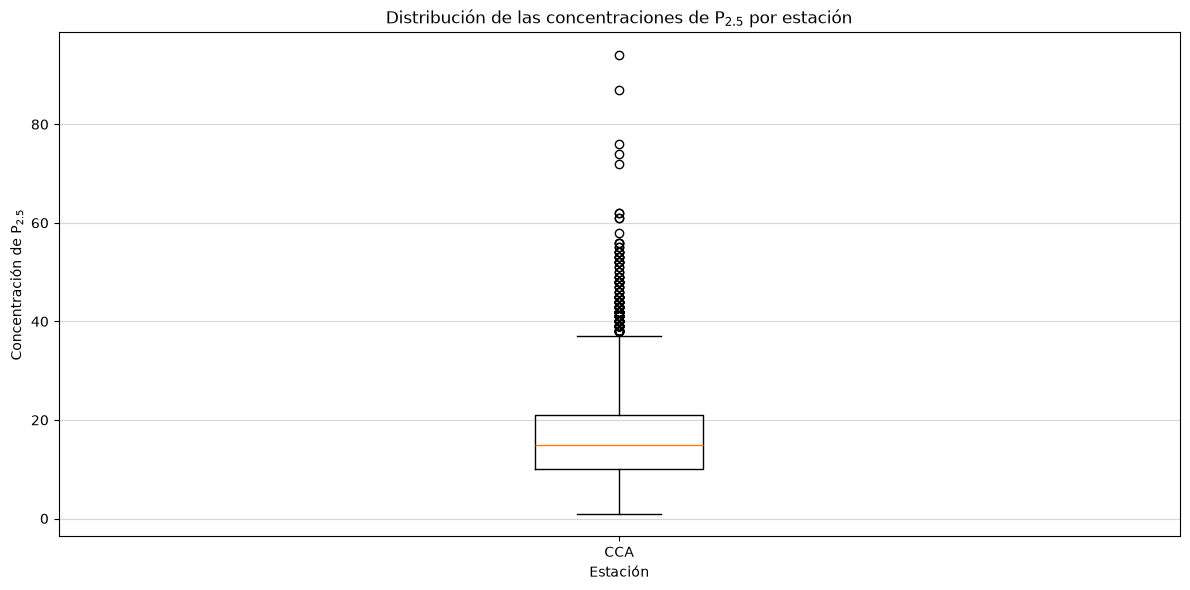

In [198]:
orden= resumen_p25.index.tolist()

fig,ax= plt.subplots(figsize=(12,6))

ax.boxplot([p25_imputado[e] for e in orden],
    tick_labels=orden,
    showfliers=True)

ax.set_title("Distribución de las concentraciones de P$_{2.5}$ por estación")
ax.set_xlabel("Estación")
ax.set_ylabel("Concentración de P$_{2.5}$")
ax.tick_params(axis="x")
ax.grid(axis="y",alpha=0.5)

plt.tight_layout()
plt.show()

Se calcula perfil horario mediano por estación.

Agrupamos las observaciones según la hora $h\in\{0,1,\ldots,23\}$. Calculamos la mediana de las concentraciones registradas a una misma hora $M_i(h)=\operatorname{mediana}\left\{X_{i,t}:\operatorname{hora}(t)=h\right\}$. La mediana es útil porque las mediciones presentan asimetría con concentraciones elevadas que pueden influir sobre la media.

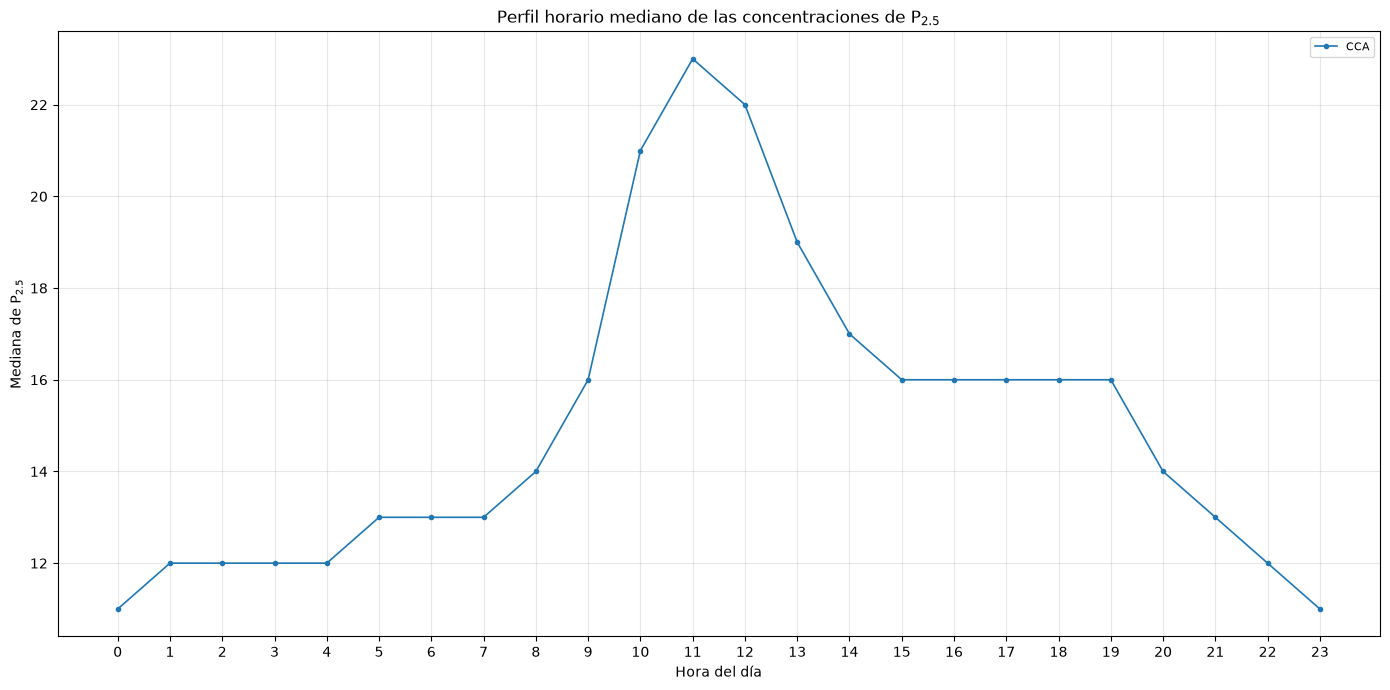

In [202]:
# Perfil horario mediano

perfil_horario= p25_imputado.groupby(p25_imputado.index.hour).median()

perfil_horario.index.name="hora"


fig, ax = plt.subplots(figsize=(14, 7))

for estacion in estaciones_finales:

    ax.plot(
        perfil_horario.index,
        perfil_horario[estacion],
        marker="o",
        markersize=3,
        linewidth=1.2,
        label=estacion
    )

ax.set_title(
    "Perfil horario mediano de las concentraciones de P$_{2.5}$"
)

ax.set_xlabel("Hora del día")
ax.set_ylabel("Mediana de P$_{2.5}$")

ax.set_xticks(range(24))

ax.grid(alpha=0.3)

ax.legend(
    ncol=2,
    fontsize=8
)

plt.tight_layout()
plt.show()

Para CCA, la hora del máximo mediano es la 11, con valor 23

In [203]:
# Hora del máximo típico por estación

resumen_horario = pd.DataFrame({
    "hora_maxima": perfil_horario.idxmax(),
    "valor_mediano_maximo": perfil_horario.max()
})

print("Hora del máximo mediano por estación:")
resumen_horario.sort_values("hora_maxima").round(2)

Hora del máximo mediano por estación:


,hora_maxima,valor_mediano_maximo
CCA,11,23.0


## 6. Constracción del panel final

Después del proceso de limpieza
- 1 estación
- 8760 observaciones horarias
- frecuencia regular de una hora
- Valores faltantes imputados
- Identificación de las observaciones imputadas

Transformamos la matriz en formato ancho a un panel de formato largo. Cada observación representa una combinación $(i,t)$

Resumen
- Se convierte `p25_imputado` de formato ancho a largo con `melt`.
- Se guarda como `panel_p25_2025.csv`
- panel final: 8760 filas × 7 columnas
- 1 estación: CCA
- 8760 instantes temporales
- 0 faltantes
- 140 imputados
- 140 observaciones en baja disponibilidad

In [217]:
# Panel de concentraciones

panel_p25= p25_imputado.reset_index().melt(id_vars="timestamp", var_name="estacion", value_name="p25")  

# Indicador de valores imputados
panel_imp= mascara_imputados.reset_index().melt(id_vars="timestamp",var_name="estacion",value_name="imputado")

# Integracion
panel_final=panel_p25.merge(panel_imp,on=["timestamp","estacion"],how="left")

# Bandera de baja disponibilidad de la red
panel_final["baja_disponibilidad"] = panel_final["timestamp"].map(disponibilidad_panel["baja_disponibilidad"])

# Recuperamos la convención temporal original FECHA + HORA
tiempo_fuente =panel_final["timestamp"]- pd.Timedelta(hours=1)

panel_final["fecha"] =tiempo_fuente.dt.normalize()

panel_final["hora"] =((panel_final["timestamp"].dt.hour - 1) % 24) + 1

# Reordenamos columnas

panel_final = panel_final[ ["timestamp","fecha","hora","estacion","p25","imputado","baja_disponibilidad"] ]

# Orden estación-tiempo
panel_final = panel_final.sort_values(["estacion", "timestamp"]).reset_index(drop=True)


print("Dimensiones del panel final:")
print(panel_final.shape)

print("\nNúmero de estaciones:")
print(panel_final["estacion"].nunique())

print("\nNúmero de instantes temporales:")
print(panel_final["timestamp"].nunique())

print("\nValores faltantes en P25:")
print(panel_final["p25"].isna().sum())

print("\nObservaciones imputadas:")
print(panel_final["imputado"].sum())

print("\nObservaciones en periodos de baja disponibilidad:")
print(panel_final["baja_disponibilidad"].sum())

print("\nCombinaciones estación-timestamp duplicadas:")
print(panel_final.duplicated(subset=["estacion", "timestamp"]).sum())

Dimensiones del panel final:
(8760, 7)

Número de estaciones:
1

Número de instantes temporales:
8760

Valores faltantes en P25:
0

Observaciones imputadas:
140

Observaciones en periodos de baja disponibilidad:
140

Combinaciones estación-timestamp duplicadas:
0


In [218]:
print("\nPrimeras observaciones:")
display(panel_final.head(15))


# Guardado
nombre_archivo = "panel_p25_2025.csv"
panel_final.to_csv(nombre_archivo,index=False)

print("\nPanel guardado como:")
print(nombre_archivo)


Primeras observaciones:


,timestamp,fecha,hora,estacion,p25,imputado,baja_disponibilidad
0,2025-01-01 01:00:00,2025-01-01,1,CCA,30.0,False,False
1,2025-01-01 02:00:00,2025-01-01,2,CCA,36.0,False,False
2,2025-01-01 03:00:00,2025-01-01,3,CCA,42.0,False,False
3,2025-01-01 04:00:00,2025-01-01,4,CCA,52.0,False,False
4,2025-01-01 05:00:00,2025-01-01,5,CCA,61.0,False,False
5,2025-01-01 06:00:00,2025-01-01,6,CCA,50.0,False,False
6,2025-01-01 07:00:00,2025-01-01,7,CCA,54.0,False,False
7,2025-01-01 08:00:00,2025-01-01,8,CCA,48.0,False,False
8,2025-01-01 09:00:00,2025-01-01,9,CCA,38.0,False,False
9,2025-01-01 10:00:00,2025-01-01,10,CCA,39.0,False,False



Panel guardado como:
panel_p25_2025.csv


Finalmente, se ha limpiado, diagnosticado, seleccionado, imputado y estructurado un panel horario de $PM_{2.5}$ para 2025. La única estación que cumple los criterios finales de cobertura $>85\%$ y $g<48$ es CCA, y el panel final queda con 8760 observaciones horarias y 140 valores imputados.